# 1. 라이브러리 및 경로 설정

In [1]:
# ============================================================
# 1. 라이브러리 및 경로 설정
# ============================================================

import json
import re
import warnings
from pathlib import Path
from html import unescape

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import spearmanr, ttest_ind, mannwhitneyu
from sklearn.feature_extraction.text import TfidfTransformer, TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

warnings.filterwarnings("ignore")

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False


def find_project_root() -> Path:
    for candidate in (Path.cwd(), *Path.cwd().parents):
        if (candidate / "data").exists():
            return candidate
    return Path.cwd()


PROJECT_ROOT = find_project_root()

RAW_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
ANALYSIS_DIR = PROCESSED_DIR / "analysis"
SECTION_DIR = ANALYSIS_DIR / "section_deep_validation"

REPORT_JSON_DIR = PROCESSED_DIR / "dart_full_reports"
SEED_DICT_PATH = RAW_DIR / "seed_dictionary.csv"
COMPANY_MASTER_PATH = RAW_DIR / "company_master.csv"

SECTION_DIR.mkdir(parents=True, exist_ok=True)

print("PROJECT_ROOT:", PROJECT_ROOT)
print("REPORT_JSON_DIR:", REPORT_JSON_DIR)
print("SEED_DICT_PATH:", SEED_DICT_PATH)
print("COMPANY_MASTER_PATH:", COMPANY_MASTER_PATH)
print("SECTION_DIR:", SECTION_DIR)

PROJECT_ROOT: c:\Users\duswl\OneDrive\바탕 화면\duswls3247\비정형 데이터 처리\Final
REPORT_JSON_DIR: c:\Users\duswl\OneDrive\바탕 화면\duswls3247\비정형 데이터 처리\Final\data\processed\dart_full_reports
SEED_DICT_PATH: c:\Users\duswl\OneDrive\바탕 화면\duswls3247\비정형 데이터 처리\Final\data\raw\seed_dictionary.csv
COMPANY_MASTER_PATH: c:\Users\duswl\OneDrive\바탕 화면\duswls3247\비정형 데이터 처리\Final\data\raw\company_master.csv
SECTION_DIR: c:\Users\duswl\OneDrive\바탕 화면\duswls3247\비정형 데이터 처리\Final\data\processed\analysis\section_deep_validation


# 2. 데이터 불러오기

In [2]:
# ============================================================
# 2. 데이터 불러오기
# ============================================================

json_files = sorted(REPORT_JSON_DIR.glob("*.json"))

if len(json_files) == 0:
    raise FileNotFoundError("dart_full_reports 폴더에 json 파일이 없습니다.")

seed_df = pd.read_csv(SEED_DICT_PATH)
seed_df.columns = [str(c).strip() for c in seed_df.columns]

required_seed_cols = ["dimension", "seed_term", "pattern"]

for col in required_seed_cols:
    if col not in seed_df.columns:
        raise ValueError(f"seed_dictionary.csv에 {col} 컬럼이 없습니다.")

seed_df["dimension"] = seed_df["dimension"].astype(str).str.strip()
seed_df["seed_term"] = seed_df["seed_term"].astype(str).str.strip()
seed_df["pattern"] = seed_df["pattern"].astype(str).str.strip()

seed_df = seed_df[
    (seed_df["pattern"] != "") &
    (seed_df["pattern"].str.lower() != "nan") &
    (seed_df["dimension"].isin(["E", "S", "G"]))
].copy()

grade_df = pd.read_csv(COMPANY_MASTER_PATH, dtype={"stock_code": str})
grade_df.columns = [str(c).strip() for c in grade_df.columns]

grade_df["stock_code"] = (
    grade_df["stock_code"]
    .astype(str)
    .str.replace(r"\.0$", "", regex=True)
    .str.zfill(6)
)

grade_df["fiscal_year"] = grade_df["fiscal_year"].astype(int)

if "esg_year" in grade_df.columns:
    grade_df["esg_year"] = grade_df["esg_year"].astype(int)
else:
    grade_df["esg_year"] = grade_df["fiscal_year"] + 1

grade_map = {
    "D": 0,
    "C": 1,
    "B": 2,
    "B+": 3,
    "A": 4,
    "A+": 5,
    "S": 6
}

if "esg_grade_num" not in grade_df.columns:
    grade_df["esg_grade"] = grade_df["esg_grade"].astype(str).str.strip()
    grade_df["esg_grade_num"] = grade_df["esg_grade"].map(grade_map)

print("JSON 파일 수:", len(json_files))
print("seed 수:", len(seed_df))
print(seed_df["dimension"].value_counts())
print("ESG 등급 데이터 수:", len(grade_df))
print(grade_df[["company_name", "stock_code", "fiscal_year", "esg_year", "esg_grade", "esg_grade_num"]].head())

JSON 파일 수: 381
seed 수: 30
dimension
E    10
S    10
G    10
Name: count, dtype: int64
ESG 등급 데이터 수: 381
  company_name stock_code  fiscal_year  esg_year esg_grade  esg_grade_num
0         삼성전자     005930         2022      2023         A              4
1         삼성전자     005930         2023      2024        B+              3
2         삼성전자     005930         2024      2025         A              4
3          BYC     001460         2022      2023         D              0
4          BYC     001460         2023      2024         D              0


# 3. JSON에서 섹션 텍스트 추출

In [3]:
# ============================================================
# 3. JSON에서 text / lineage 추출
# ============================================================

def flatten_records(obj):
    records = []

    text_keys = [
        "text",
        "full_text",
        "unit_text",
        "section_text",
        "content",
        "paragraph",
        "passage"
    ]

    lineage_keys = [
        "lineage",
        "section",
        "section_title",
        "title",
        "heading",
        "chapter",
        "toc"
    ]

    if isinstance(obj, dict):
        keys = set(obj.keys())

        has_text = any(k in keys for k in text_keys)

        if has_text:
            rec = {}

            for k in text_keys:
                if k in obj:
                    rec["text"] = obj.get(k)
                    rec["text_source_key"] = k
                    break

            for k in lineage_keys:
                if k in obj:
                    rec["lineage"] = obj.get(k)
                    rec["lineage_source_key"] = k
                    break

            if "lineage" not in rec:
                rec["lineage"] = ""
                rec["lineage_source_key"] = ""

            records.append(rec)

        for v in obj.values():
            records.extend(flatten_records(v))

    elif isinstance(obj, list):
        for item in obj:
            records.extend(flatten_records(item))

    return records


rows = []

for path in json_files:
    file_name = path.name

    m = re.match(r"(\d{6})_(\d{4})\.json", file_name)

    if m:
        stock_code = m.group(1)
        fiscal_year = int(m.group(2))
    else:
        stock_code = ""
        fiscal_year = np.nan

    with open(path, "r", encoding="utf-8") as f:
        data = json.load(f)

    records = flatten_records(data)

    for i, rec in enumerate(records):
        lineage = rec.get("lineage", "")

        if isinstance(lineage, list):
            lineage = " > ".join([str(x) for x in lineage])
        else:
            lineage = str(lineage)

        text = str(rec.get("text", ""))

        rows.append({
            "source_file": file_name,
            "stock_code": stock_code,
            "fiscal_year": fiscal_year,
            "row_order": i + 1,
            "lineage": lineage,
            "text": text,
            "text_source_key": rec.get("text_source_key", ""),
            "lineage_source_key": rec.get("lineage_source_key", "")
        })

json_text_df = pd.DataFrame(rows)

json_text_df["stock_code"] = json_text_df["stock_code"].astype(str).str.zfill(6)
json_text_df["fiscal_year"] = json_text_df["fiscal_year"].astype(int)
json_text_df["esg_year"] = json_text_df["fiscal_year"] + 1
json_text_df["analysis_unit"] = (
    json_text_df["stock_code"] + "x" + json_text_df["fiscal_year"].astype(str)
)

json_text_df["text"] = json_text_df["text"].fillna("").astype(str)
json_text_df["text_chars"] = json_text_df["text"].str.len()

print("추출된 텍스트 행 수:", len(json_text_df))
print("분석 단위 수:", json_text_df["analysis_unit"].nunique())
print(json_text_df.head())

추출된 텍스트 행 수: 381
분석 단위 수: 381
        source_file stock_code  fiscal_year  row_order lineage  \
0  000020_2022.json     000020         2022          1           
1  000020_2023.json     000020         2023          1           
2  000020_2024.json     000020         2024          1           
3  000040_2022.json     000040         2022          1           
4  000040_2023.json     000040         2023          1           

                                                text text_source_key  \
0  사업보고서 \n5.0 \n동화약품주식회사 \n\nC \nA \n110111-0043...       full_text   
1  감사보고서 \n4.1 \n동화약품 주식회사 \n\n00469373 \n1000000...       full_text   
2  연결감사보고서 \n6.0 \n동화약품 주식회사 \n\n00469373 \n10000...       full_text   
3  사업보고서 \n5.0 \nKR모터스 \n\nC \nA \n160111-0007032...       full_text   
4  연결감사보고서 \n3.5 \n케이알모터스(주) \n\n00260295 \n10000...       full_text   

  lineage_source_key  esg_year analysis_unit  text_chars  
0                         2023   000020x2022      432677  
1                     

# 4. 섹션 표준화 추출

- II. 사업의 내용
- IV. 이사의 경영진단 및 분석의견
- VI. 이사회 등 회사의 기관에 관한 사항
- VIII. 임원 및 직원 등에 관한 사항
- XI. 그 밖에 투자자 보호를 위하여 필요한 사항

In [4]:
# ============================================================
# 4. 주요 섹션 표준화 및 필터링
# ============================================================

roman_to_title = {
    "II": "II. 사업의 내용",
    "IV": "IV. 이사의 경영진단 및 분석의견",
    "VI": "VI. 이사회 등 회사의 기관에 관한 사항",
    "VIII": "VIII. 임원 및 직원 등에 관한 사항",
    "XI": "XI. 그 밖에 투자자 보호를 위하여 필요한 사항",
}

selected_romans = ["II", "IV", "VI", "VIII", "XI"]

roman_replace_map = {
    "Ⅰ": "I",
    "Ⅱ": "II",
    "Ⅲ": "III",
    "Ⅳ": "IV",
    "Ⅴ": "V",
    "Ⅵ": "VI",
    "Ⅶ": "VII",
    "Ⅷ": "VIII",
    "Ⅸ": "IX",
    "Ⅹ": "X",
    "Ⅺ": "XI",
    "Ⅻ": "XII",
}


def normalize_roman_text(text):
    text = str(text)
    for k, v in roman_replace_map.items():
        text = text.replace(k, v)
    return text


def extract_section_roman(lineage="", text=""):
    raw = normalize_roman_text(str(lineage))

    if raw.strip() == "" or raw.lower() == "nan":
        raw = normalize_roman_text(str(text)[:1000])

    pattern = r"\b(XI|VIII|VI|IV|II)\b\.?"

    match = re.search(pattern, raw)

    if match:
        return match.group(1)

    return "미분류"


json_text_df["section_roman"] = json_text_df.apply(
    lambda row: extract_section_roman(
        lineage=row.get("lineage", ""),
        text=row.get("text", "")
    ),
    axis=1
)

json_text_df["section_clean"] = json_text_df["section_roman"].map(roman_to_title)
json_text_df["section_clean"] = json_text_df["section_clean"].fillna("미분류")

section_text_df = json_text_df[
    json_text_df["section_roman"].isin(selected_romans)
].copy()

print("선택 섹션 텍스트 행 수:", len(section_text_df))
print("선택 섹션별 행 수")
print(section_text_df["section_clean"].value_counts())

if len(section_text_df) == 0:
    raise ValueError("2,4,6,8,11 섹션이 추출되지 않았습니다. lineage/text 구조를 확인해야 합니다.")

선택 섹션 텍스트 행 수: 176
선택 섹션별 행 수
section_clean
II. 사업의 내용                     142
VIII. 임원 및 직원 등에 관한 사항          18
VI. 이사회 등 회사의 기관에 관한 사항          7
IV. 이사의 경영진단 및 분석의견              5
XI. 그 밖에 투자자 보호를 위하여 필요한 사항      4
Name: count, dtype: int64


# 5. 섹션 텍스트에서 ESG passage 추출
- `seed_dictionary.csv`의 정규표현식과 매칭
- ESG seed 단어가 포함된 문장만 passage 후보로 추출
- passage별 E/S/G 차원 부여

In [5]:
# ============================================================
# 5. ESG passage 후보 추출
# ============================================================

def normalize_text(text):
    text = unescape(str(text))
    text = re.sub(r"[ \t\r\f]+", " ", text)
    text = re.sub(r"\n[ \t]*", "\n", text)
    text = re.sub(r"\n{3,}", "\n\n", text)
    return text.strip()


def split_passage_candidates(text):
    text = normalize_text(text)

    if not text:
        return []

    chunks = re.split(
        r"\n{2,}|(?<=[다음임함음요오])\.\s+|(?<=[.!?。])\s+",
        text
    )

    passages = []

    for chunk in chunks:
        passage = normalize_text(chunk)

        if 40 <= len(passage) <= 2000:
            passages.append(passage)

    return passages


def count_pattern(text, pattern):
    try:
        return len(re.findall(str(pattern), str(text), flags=re.IGNORECASE))
    except re.error:
        return 0


passage_rows = []

for _, row in section_text_df.iterrows():
    passages = split_passage_candidates(row["text"])

    for sent_idx, passage in enumerate(passages):
        matched_by_dim = {}
        matched_count_by_dim = {}

        for _, seed in seed_df.iterrows():
            dim = seed["dimension"]
            seed_term = seed["seed_term"]
            pattern = seed["pattern"]

            cnt = count_pattern(passage, pattern)

            if cnt > 0:
                matched_by_dim.setdefault(dim, set()).add(seed_term)
                matched_count_by_dim[dim] = matched_count_by_dim.get(dim, 0) + cnt

        for dim, terms in matched_by_dim.items():
            passage_rows.append({
                "analysis_unit": row["analysis_unit"],
                "stock_code": row["stock_code"],
                "fiscal_year": row["fiscal_year"],
                "esg_year": row["esg_year"],
                "source_file": row["source_file"],
                "section_roman": row["section_roman"],
                "section_clean": row["section_clean"],
                "sentence_index": sent_idx,
                "dimension": dim,
                "passage": passage,
                "matched_terms": "|".join(sorted(terms)),
                "matched_term_count": len(terms),
                "match_count": matched_count_by_dim.get(dim, 0),
                "passage_chars": len(passage)
            })

section_passage_df = pd.DataFrame(passage_rows)

print("ESG passage 수:", len(section_passage_df))
print("분석 단위 수:", section_passage_df["analysis_unit"].nunique())
print(section_passage_df.head())

section_passage_path = SECTION_DIR / "section_esg_passages.csv"
section_passage_df.to_csv(section_passage_path, index=False, encoding="utf-8-sig")
print("저장 완료:", section_passage_path)

ESG passage 수: 53890
분석 단위 수: 176
  analysis_unit stock_code  fiscal_year  esg_year       source_file  \
0   000020x2023     000020         2023      2024  000020_2023.json   
1   000020x2023     000020         2023      2024  000020_2023.json   
2   000020x2023     000020         2023      2024  000020_2023.json   
3   000020x2023     000020         2023      2024  000020_2023.json   
4   000020x2023     000020         2023      2024  000020_2023.json   

  section_roman section_clean  sentence_index dimension  \
0            II    II. 사업의 내용               6         G   
1            II    II. 사업의 내용              13         G   
2            II    II. 사업의 내용              32         S   
3            II    II. 사업의 내용              32         G   
4            II    II. 사업의 내용             105         G   

                                             passage matched_terms  \
0  우리는 재무제표 감사와 관련된 대한민국의 윤리적 요구사항에 따라 회사로부터 독립적이...            윤리   
1  - 이사회에서 승인된 최근 사업계획, 과거 실적 및 산업보고서 비교를 통해

# 6. 형태소 분석 및 토큰화

- 사용 도구: `PeCab`
- 역할: 한국어 문장을 형태소 단위로 나누는 분석기
- 단순 공백 분리만 하면 조사나 어미가 붙은 같은 단어가 서로 다른 단어처럼 처리될 수 있어 Pecab은 이를 더 작은 형태소 단위로 나누어 분석 품질을 높인다

In [6]:
# ============================================================
# 6. 형태소 분석 및 토큰화
# ============================================================

import re

def clean_korean_text(text):
    text = str(text)
    text = re.sub(r"[^가-힣a-zA-Z0-9\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

try:
    from pecab import PeCab
    tokenizer_model = PeCab()
    tokenizer_name = "PeCab"

    def morph_tokenize(text):
        text = clean_korean_text(text)
        return tokenizer_model.morphs(text)

except Exception as e:
    print("PeCab 사용 불가. 기본 split 토큰화를 사용합니다.")
    print("오류:", e)
    tokenizer_name = "split"

    def morph_tokenize(text):
        text = clean_korean_text(text)
        return text.split()

section_passage_df["tokens"] = section_passage_df["passage"].apply(morph_tokenize)

section_passage_df["morph_text"] = section_passage_df["tokens"].apply(
    lambda x: " ".join(x)
)

print("사용 토크나이저:", tokenizer_name)
print(section_passage_df[["passage", "tokens", "morph_text"]].head())

사용 토크나이저: PeCab
                                             passage  \
0  우리는 재무제표 감사와 관련된 대한민국의 윤리적 요구사항에 따라 회사로부터 독립적이...   
1  - 이사회에서 승인된 최근 사업계획, 과거 실적 및 산업보고서 비교를 통해 추정 매...   
2  또한, 우리는 독립성 관련 윤리적 요구사항들을 준수하고, 우리의 독립성 문제와 관련...   
3  또한, 우리는 독립성 관련 윤리적 요구사항들을 준수하고, 우리의 독립성 문제와 관련...   
4  당사는 1976년 3월 24일에 주식을 한국거래소에 상장하였으며 당기말 현재 주요 ...   

                                              tokens  \
0  [우리, 는, 재무제표, 감사, 와, 관련, 된, 대한민국, 의, 윤리, 적, 요구...   
1  [이사회, 에서, 승인, 된, 최근, 사업, 계획, 과거, 실적, 및, 산업, 보고...   
2  [또한, 우리, 는, 독립성, 관련, 윤리, 적, 요구, 사항, 들, 을, 준, 수...   
3  [또한, 우리, 는, 독립성, 관련, 윤리, 적, 요구, 사항, 들, 을, 준, 수...   
4  [당사, 는, 1, 9, 7, 6, 년, 3, 월, 2, 4, 일, 에, 주식, 을...   

                                          morph_text  
0  우리 는 재무제표 감사 와 관련 된 대한민국 의 윤리 적 요구 사항 에 따라 회사 ...  
1  이사회 에서 승인 된 최근 사업 계획 과거 실적 및 산업 보고서 비교 를 통해 추 ...  
2  또한 우리 는 독립성 관련 윤리 적 요구 사항 들 을 준 수 하 고 우리 의 독립성...  
3  또한 우리 는 독립성 관련 윤리 적 요구 사항 들 을 준 수 하 고 우리 의 독립성...  
4  당사 는 1 9 7 6 년 3 월 2 4 일 에 주식 을 

# 7. 기업-연도-섹션 document 생성

- 원문 기반 `document` 생성
- 형태소 기반 `morph_document` 생성
- 섹션 텍스트 길이와 1,000자당 seed 밀도 계산

In [7]:
# ============================================================
# 7. 기업-연도-섹션 document 생성
# ============================================================

section_doc_df = (
    section_passage_df
    .groupby(
        [
            "analysis_unit",
            "stock_code",
            "fiscal_year",
            "esg_year",
            "section_roman",
            "section_clean"
        ],
        as_index=False
    )
    .agg(
        document=("passage", lambda x: " ".join(x.astype(str))),
        morph_document=("morph_text", lambda x: " ".join(x.astype(str))),
        passage_count=("passage", "count"),
        seed_match_count=("match_count", "sum"),
        e_passage_count=("dimension", lambda x: (x == "E").sum()),
        s_passage_count=("dimension", lambda x: (x == "S").sum()),
        g_passage_count=("dimension", lambda x: (x == "G").sum()),
    )
)

# 섹션 원문 길이 정보 결합
section_len_df = (
    section_text_df
    .groupby(
        [
            "analysis_unit",
            "stock_code",
            "fiscal_year",
            "section_roman",
            "section_clean"
        ],
        as_index=False
    )
    .agg(
        section_text_chars=("text_chars", "sum"),
        section_text_rows=("text", "count")
    )
)

section_doc_df = pd.merge(
    section_doc_df,
    section_len_df,
    on=[
        "analysis_unit",
        "stock_code",
        "fiscal_year",
        "section_roman",
        "section_clean"
    ],
    how="left"
)

section_doc_df["seed_per_1000_chars"] = (
    section_doc_df["seed_match_count"] /
    section_doc_df["section_text_chars"].replace(0, np.nan) * 1000
)

section_doc_df = section_doc_df.fillna(0)

print("기업-연도-섹션 document 수:", len(section_doc_df))
print(section_doc_df.head())

기업-연도-섹션 document 수: 176
  analysis_unit stock_code  fiscal_year  esg_year section_roman section_clean  \
0   000020x2023     000020         2023      2024            II    II. 사업의 내용   
1   000020x2024     000020         2024      2025            II    II. 사업의 내용   
2   000050x2022     000050         2022      2023            II    II. 사업의 내용   
3   000050x2023     000050         2023      2024            II    II. 사업의 내용   
4   000050x2024     000050         2024      2025            II    II. 사업의 내용   

                                            document  \
0  우리는 재무제표 감사와 관련된 대한민국의 윤리적 요구사항에 따라 회사로부터 독립적이...   
1  우리는 연결재무제표 감사와 관련된 대한민국의 윤리적 요구사항에 따라 회사로부터 독립...   
2  이사회 등 회사의 기관에 관한 사항 \n----------------------- ...   
3  우리는 재무제표감사와 관련된 대한민국의 윤리적 요구사항에 따라 회사로부터 독립적이며...   
4  우리는 연결재무제표감사와 관련된 대한민국의 윤리적 요구사항에 따라 연결회사로부터 독...   

                                      morph_document  passage_count  \
0  우리 는 재무제표 감사 와 관련 된 대한민국 의 윤리 적 요구 사항 에 따라 회사 ...            159   
1  우리 는 연

# 8. seed count score + seed TF-IDF score 생성

- seed dictionary의 각 단어가 document 안에서 몇 번 등장하는지 계산
- E/S/G별 seed count score 생성
- seed 출현 횟수를 TF-IDF 값으로 변환
- E/S/G별 seed TF-IDF score 생성

In [8]:
# ============================================================
# 8. seed count score + seed TF-IDF score 생성
# ============================================================

from sklearn.feature_extraction.text import TfidfTransformer

seed_count_feature_df = section_doc_df[
    [
        "analysis_unit",
        "stock_code",
        "fiscal_year",
        "esg_year",
        "section_roman",
        "section_clean"
    ]
].copy()

seed_count_cols = []

for idx, seed in seed_df.reset_index(drop=True).iterrows():
    dim = seed["dimension"]
    seed_term = seed["seed_term"]
    pattern = seed["pattern"]

    safe_term = re.sub(r"[^가-힣a-zA-Z0-9_]+", "_", str(seed_term))
    col = f"seed_count_{dim}_{idx}_{safe_term}"

    seed_count_feature_df[col] = section_doc_df["document"].apply(
        lambda x: count_pattern(x, pattern)
    )

    seed_count_cols.append(col)

for dim in ["E", "S", "G"]:
    dim_cols = [
        c for c in seed_count_cols
        if c.startswith(f"seed_count_{dim}_")
    ]

    seed_count_feature_df[f"seed_count_score_{dim}"] = (
        seed_count_feature_df[dim_cols].sum(axis=1)
    )

seed_count_feature_df["seed_count_score_total"] = (
    seed_count_feature_df["seed_count_score_E"] +
    seed_count_feature_df["seed_count_score_S"] +
    seed_count_feature_df["seed_count_score_G"]
)

# TF-IDF 변환
tfidf_transformer = TfidfTransformer()
tfidf_matrix = tfidf_transformer.fit_transform(
    seed_count_feature_df[seed_count_cols].values
)

tfidf_cols = [
    c.replace("seed_count_", "seed_tfidf_")
    for c in seed_count_cols
]

tfidf_df = pd.DataFrame(
    tfidf_matrix.toarray(),
    columns=tfidf_cols
)

seed_tfidf_feature_df = pd.concat(
    [
        seed_count_feature_df[
            [
                "analysis_unit",
                "stock_code",
                "fiscal_year",
                "esg_year",
                "section_roman",
                "section_clean"
            ]
        ].reset_index(drop=True),
        tfidf_df.reset_index(drop=True)
    ],
    axis=1
)

for dim in ["E", "S", "G"]:
    dim_cols = [
        c for c in tfidf_cols
        if c.startswith(f"seed_tfidf_{dim}_")
    ]

    seed_tfidf_feature_df[f"seed_tfidf_score_{dim}"] = (
        seed_tfidf_feature_df[dim_cols].sum(axis=1)
    )

seed_tfidf_feature_df["seed_tfidf_score_total"] = (
    seed_tfidf_feature_df["seed_tfidf_score_E"] +
    seed_tfidf_feature_df["seed_tfidf_score_S"] +
    seed_tfidf_feature_df["seed_tfidf_score_G"]
)

# 기본 feature 데이터 결합
base_feature_df = pd.merge(
    section_doc_df,
    seed_count_feature_df[
        [
            "analysis_unit",
            "stock_code",
            "fiscal_year",
            "esg_year",
            "section_roman",
            "section_clean",
            "seed_count_score_E",
            "seed_count_score_S",
            "seed_count_score_G",
            "seed_count_score_total"
        ]
    ],
    on=[
        "analysis_unit",
        "stock_code",
        "fiscal_year",
        "esg_year",
        "section_roman",
        "section_clean"
    ],
    how="left"
)

base_feature_df = pd.merge(
    base_feature_df,
    seed_tfidf_feature_df[
        [
            "analysis_unit",
            "stock_code",
            "fiscal_year",
            "esg_year",
            "section_roman",
            "section_clean",
            "seed_tfidf_score_E",
            "seed_tfidf_score_S",
            "seed_tfidf_score_G",
            "seed_tfidf_score_total"
        ]
    ],
    on=[
        "analysis_unit",
        "stock_code",
        "fiscal_year",
        "esg_year",
        "section_roman",
        "section_clean"
    ],
    how="left"
)

print(base_feature_df.head())

  analysis_unit stock_code  fiscal_year  esg_year section_roman section_clean  \
0   000020x2023     000020         2023      2024            II    II. 사업의 내용   
1   000020x2024     000020         2024      2025            II    II. 사업의 내용   
2   000050x2022     000050         2022      2023            II    II. 사업의 내용   
3   000050x2023     000050         2023      2024            II    II. 사업의 내용   
4   000050x2024     000050         2024      2025            II    II. 사업의 내용   

                                            document  \
0  우리는 재무제표 감사와 관련된 대한민국의 윤리적 요구사항에 따라 회사로부터 독립적이...   
1  우리는 연결재무제표 감사와 관련된 대한민국의 윤리적 요구사항에 따라 회사로부터 독립...   
2  이사회 등 회사의 기관에 관한 사항 \n----------------------- ...   
3  우리는 재무제표감사와 관련된 대한민국의 윤리적 요구사항에 따라 회사로부터 독립적이며...   
4  우리는 연결재무제표감사와 관련된 대한민국의 윤리적 요구사항에 따라 연결회사로부터 독...   

                                      morph_document  passage_count  \
0  우리 는 재무제표 감사 와 관련 된 대한민국 의 윤리 적 요구 사항 에 따라 회사 ...            159   
1  우리 는 연결 재무제표 감사 와 관련 된 대한민국 의 윤

# 9. 형태소 기반 FastText 학습

- FastText 단어 임베딩 모델 학습
- ESG 문장에서 단어들이 어떤 문맥으로 함께 쓰이는지 학습

In [9]:
# ============================================================
# 9. 형태소 기반 FastText 학습
# ============================================================

from gensim.models import FastText

sentences = section_passage_df["tokens"].tolist()

print("FastText 학습 문장 수:", len(sentences))
print(sentences[:2])

ft_model = FastText(
    sentences=sentences,
    vector_size=100,
    window=5,
    min_count=2,
    workers=4,
    sg=1,
    epochs=10
)

print("FastText vocab size:", len(ft_model.wv))

FastText 학습 문장 수: 53890
[['우리', '는', '재무제표', '감사', '와', '관련', '된', '대한민국', '의', '윤리', '적', '요구', '사항', '에', '따라', '회사', '로부터', '독립', '적', '이', '며', '그러', '한', '요구사항', '에', '따른', '기타', '의', '윤리', '적', '책임', '들', '을', '이행', '하', '였', '습', '니', '다'], ['이사회', '에서', '승인', '된', '최근', '사업', '계획', '과거', '실적', '및', '산업', '보고서', '비교', '를', '통해', '추', '정', '매', '출성', '장률', '및', '영구', '성장률', '을', '포함', '한', '사용', '가치', '산정', '시', '경영진', '이', '사용', '한', '주요', '가정', '검토']]
FastText vocab size: 13549


# 10. FastText 기반 expanded dictionary 후보 생성 및 필터링

- seed term을 기준으로 FastText 유사 단어 탐색
- 유사도 기준값별 확장 단어 후보 생성
- 숫자, 고유명사, 의미 없는 단어 등 노이즈 제거
- 유효한 확장 단어만 선별

In [10]:
# ============================================================
# 10. expanded dictionary 후보 생성 및 필터링
# ============================================================

company_name_set = set()

if "company_name" in grade_df.columns:
    company_name_set = set(
        grade_df["company_name"]
        .dropna()
        .astype(str)
        .str.strip()
        .tolist()
    )

manual_stopwords = {
    "및", "또는", "등", "관련", "사항", "당사", "회사", "사업", "내용",
    "기준", "대상", "경우", "통해", "위해", "대한", "있는", "없는",
    "주요", "보고서", "제", "년", "월", "일"
}

def is_valid_expanded_term(term):
    term = str(term).strip()

    if len(term) < 2:
        return False

    if term in manual_stopwords:
        return False

    if term in company_name_set:
        return False

    if re.fullmatch(r"\d+", term):
        return False

    if re.fullmatch(r"\d{4}년?", term):
        return False

    if re.match(r"^\d+[가-힣a-zA-Z]+", term):
        return False

    if re.search(r"[0-9]{2,}", term):
        return False

    if not re.search(r"[가-힣a-zA-Z]", term):
        return False

    return True


def expand_terms_fasttext(model, seed_terms, topn=30, threshold=0.55):
    rows = []

    for seed_term in seed_terms:
        seed_term = str(seed_term).strip()

        if not seed_term:
            continue

        try:
            similar_words = model.wv.most_similar(seed_term, topn=topn)
        except Exception:
            continue

        for word, sim in similar_words:
            if sim >= threshold:
                rows.append({
                    "seed_term": seed_term,
                    "expanded_term": word,
                    "similarity": sim
                })

    return pd.DataFrame(rows)


theta_list = [0.50, 0.55, 0.60]
seed_top_n = 10

expanded_rows = []

for theta in theta_list:
    for dim in ["E", "S", "G"]:
        seed_terms = (
            seed_df[seed_df["dimension"] == dim]["seed_term"]
            .dropna()
            .astype(str)
            .head(seed_top_n)
            .tolist()
        )

        cand_df = expand_terms_fasttext(
            ft_model,
            seed_terms,
            topn=30,
            threshold=theta
        )

        if len(cand_df) == 0:
            continue

        cand_df["theta"] = theta
        cand_df["dimension"] = dim
        cand_df["is_valid"] = cand_df["expanded_term"].apply(is_valid_expanded_term)

        expanded_rows.append(cand_df)

expanded_terms_df = (
    pd.concat(expanded_rows, ignore_index=True)
    if expanded_rows
    else pd.DataFrame()
)

print("확장 후보 단어 수:", len(expanded_terms_df))
print(expanded_terms_df.head(30))

expanded_terms_path = SECTION_DIR / "expanded_terms_candidates.csv"
expanded_terms_df.to_csv(
    expanded_terms_path,
    index=False,
    encoding="utf-8-sig"
)

valid_expanded_terms_df = expanded_terms_df[
    expanded_terms_df["is_valid"] == True
].copy()

print("필터링 후 확장 단어 수")
print(valid_expanded_terms_df.groupby(["theta", "dimension"]).size())

확장 후보 단어 수: 2002
   seed_term expanded_term  similarity  theta dimension  is_valid
0         탄소            중립    0.871203    0.5         E      True
1         탄소           기상청    0.664932    0.5         E      True
2         탄소            저감    0.654420    0.5         E      True
3         탄소            감축    0.651705    0.5         E      True
4         탄소           이산화    0.649302    0.5         E      True
5         탄소            포집    0.647757    0.5         E      True
6         탄소           발맞춘    0.644545    0.5         E      True
7         탄소           발자국    0.640246    0.5         E      True
8         탄소            결성    0.637382    0.5         E      True
9         탄소           친환경    0.623069    0.5         E      True
10        탄소           저탄소    0.610365    0.5         E      True
11        탄소        우리금융그룹    0.608624    0.5         E      True
12        탄소            상쇄    0.605808    0.5         E      True
13        탄소           이행함    0.605341    0.5         E    

# 11. expanded count score, 계산

In [11]:
# ============================================================
# 11. expanded count score 계산
# ============================================================

target_theta = 0.55

expanded_dict = {}

for dim in ["E", "S", "G"]:
    terms = (
        valid_expanded_terms_df[
            (valid_expanded_terms_df["theta"] == target_theta) &
            (valid_expanded_terms_df["dimension"] == dim)
        ]["expanded_term"]
        .dropna()
        .astype(str)
        .drop_duplicates()
        .tolist()
    )

    expanded_dict[dim] = terms

    print(f"{dim} 확장 단어 수:", len(terms))
    print(terms[:30])


expanded_feature_df = base_feature_df[
    [
        "analysis_unit",
        "stock_code",
        "fiscal_year",
        "esg_year",
        "section_roman",
        "section_clean",
        "morph_document"
    ]
].copy()

for dim in ["E", "S", "G"]:
    terms = expanded_dict[dim]
    score = pd.Series(0, index=expanded_feature_df.index)

    for term in terms:
        pattern = re.escape(term)
        score += expanded_feature_df["morph_document"].apply(
            lambda x: count_pattern(x, pattern)
        )

    expanded_feature_df[f"expanded_count_score_{dim}"] = score

expanded_feature_df["expanded_count_score_total"] = (
    expanded_feature_df["expanded_count_score_E"] +
    expanded_feature_df["expanded_count_score_S"] +
    expanded_feature_df["expanded_count_score_G"]
)

base_feature_df = pd.merge(
    base_feature_df,
    expanded_feature_df[
        [
            "analysis_unit",
            "stock_code",
            "fiscal_year",
            "esg_year",
            "section_roman",
            "section_clean",
            "expanded_count_score_E",
            "expanded_count_score_S",
            "expanded_count_score_G",
            "expanded_count_score_total"
        ]
    ],
    on=[
        "analysis_unit",
        "stock_code",
        "fiscal_year",
        "esg_year",
        "section_roman",
        "section_clean"
    ],
    how="left"
)

print(base_feature_df.head())

E 확장 단어 수: 231
['중립', '기상청', '저감', '감축', '이산화', '포집', '발맞춘', '발자국', '결성', '친환경', '저탄소', '우리금융그룹', '상쇄', '이행함', '유세', '량의', '리온', '무해', '응하', '온실가스', '로드맵', '웨이스트', '시대', '배출', '앞장설', '탄소성', '국경세', '세워', '저탄', '능동']
S 확장 단어 수: 218
['보건', '안전기', '안전띠', '안전역', '보건소', '안전도', '안전모', '안전판', '안전시설', '업안', '연구실', '출구', '반안', '안전원', '불합격', '사업주', '식생활', '도급인', '오형수', '전보', '안전계', '노동법', '소홀', '산업', '방사선', '안전사고', '당사도', '허가서', '소방법', '항산']
G 확장 단어 수: 140
['사회', '이사', '사외', '이석재', '전영준', '최현민', '외이', '이종원', '김준석', '김용균', '이병욱', '전영', '김종창', '남혜정', '신현', '이재호', '이종호', '천경훈', '신현정', '박병무', '강정원', '사내', '이장훈', '김준성', '이상규', '신선경', '김준기', '최영주', '권순범', '이재영']
  analysis_unit stock_code  fiscal_year  esg_year section_roman section_clean  \
0   000020x2023     000020         2023      2024            II    II. 사업의 내용   
1   000020x2024     000020         2024      2025            II    II. 사업의 내용   
2   000050x2022     000050         2022      2023            II    II. 사업의 내용   
3   000050x2023     00

# 12. 기준 문장 cosine similarity 계산

>기준 문장 선정 기준
- K-ESG 가이드라인의 주요 평가 항목 반영
  - 환경: 환경경영, 온실가스, 에너지, 자원, 폐기물, 환경규제
  - 사회: 안전보건, 노동, 인권, 공급망, 소비자, 지역사회
  - 지배구조: 이사회, 사외이사, 감사위원회, 내부통제, 윤리·준법, 주주권리

- seed_dictionary.csv의 핵심 단어 반영
  - E: 온실가스, 탄소, 에너지, 재생에너지, 폐기물, 환경규제
  - S: 안전보건, 인권, 근로환경, 협력사, 고객, 지역사회
  - G: 이사회, 사외이사, 감사위원회, 내부통제, 윤리경영, 준법경영

- 사업보고서 문장과 비교 가능한 문장 형태로 구성

In [12]:
# ============================================================
# 12. 기준 문장 cosine similarity
# ============================================================

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

reference_sentences = {
    "E": [
        # 환경경영 체계 / 목표
        "기업은 환경경영 목표와 추진체계를 수립하고 환경 관련 성과를 체계적으로 관리한다.",
        
        # 온실가스 / 탄소 / 기후변화
        "기업은 온실가스 배출량과 탄소배출을 측정하고 감축 목표와 실행 계획을 수립한다.",
        
        # 에너지 / 재생에너지
        "기업은 에너지 사용량을 관리하고 에너지 효율 개선과 재생에너지 사용 확대를 추진한다.",
        
        # 자원 / 원부자재 / 폐기물
        "기업은 원부자재 사용량, 폐기물 발생량, 재활용률을 관리하여 자원 사용의 효율성을 높인다.",
        
        # 환경규제 / 환경 리스크
        "기업은 환경 법규와 환경 인허가를 준수하고 환경규제 위반 및 환경 리스크를 관리한다."
    ],

    "S": [
        # 안전보건
        "기업은 임직원의 산업안전과 보건을 보호하기 위한 안전보건 관리체계를 운영한다.",
        
        # 노동 / 고용 / 근로환경
        "기업은 임직원의 고용 안정, 근로환경 개선, 복리후생 확대를 위해 노력한다.",
        
        # 인권 / 다양성
        "기업은 임직원과 이해관계자의 인권을 보호하고 다양성과 차별 방지를 위한 정책을 운영한다.",
        
        # 공급망 / 협력사
        "기업은 협력사와 공급망의 사회적 책임을 관리하고 공정한 거래와 상생협력을 추진한다.",
        
        # 고객 / 소비자 / 지역사회
        "기업은 고객 안전, 소비자 보호, 지역사회 기여 등 이해관계자에 대한 사회적 책임을 이행한다."
    ],

    "G": [
        # 이사회
        "기업은 이사회 중심의 투명한 의사결정 체계를 구축하고 이사회 운영의 전문성과 책임성을 강화한다.",
        
        # 사외이사 / 독립성
        "기업은 사외이사의 독립성과 전문성을 확보하여 이사회 독립성을 강화한다.",
        
        # 감사위원회 / 내부통제
        "기업은 감사위원회와 내부통제 제도를 통해 경영 감시와 리스크 관리 체계를 강화한다.",
        
        # 윤리경영 / 준법경영
        "기업은 윤리경영과 준법경영 체계를 구축하고 부패방지와 컴플라이언스 관리를 수행한다.",
        
        # 주주권리 / 정보공개
        "기업은 주주권리를 보호하고 경영 정보를 투명하게 공개하여 이해관계자의 신뢰를 높인다."
    ]
}


def compute_reference_cosine_scores(df, text_col="morph_document"):
    result = df[
        [
            "analysis_unit",
            "stock_code",
            "fiscal_year",
            "esg_year",
            "section_roman",
            "section_clean"
        ]
    ].copy()

    docs = df[text_col].fillna("").astype(str).tolist()

    for dim in ["E", "S", "G"]:
        refs = [
            " ".join(morph_tokenize(ref))
            for ref in reference_sentences[dim]
        ]

        corpus = refs + docs

        vectorizer = TfidfVectorizer(
            min_df=1,
            ngram_range=(1, 2),
            token_pattern=r"(?u)\b\w+\b"
        )

        X = vectorizer.fit_transform(corpus)

        ref_vecs = X[:len(refs)]
        doc_vecs = X[len(refs):]

        sim_matrix = cosine_similarity(doc_vecs, ref_vecs)

        result[f"ref_cosine_{dim}_max"] = sim_matrix.max(axis=1)
        result[f"ref_cosine_{dim}_mean"] = sim_matrix.mean(axis=1)

    result["ref_cosine_total_max"] = (
        result["ref_cosine_E_max"] +
        result["ref_cosine_S_max"] +
        result["ref_cosine_G_max"]
    )

    result["ref_cosine_total_mean"] = (
        result["ref_cosine_E_mean"] +
        result["ref_cosine_S_mean"] +
        result["ref_cosine_G_mean"]
    )

    return result


cosine_feature_df = compute_reference_cosine_scores(
    base_feature_df,
    text_col="morph_document"
)

base_feature_df = pd.merge(
    base_feature_df,
    cosine_feature_df,
    on=[
        "analysis_unit",
        "stock_code",
        "fiscal_year",
        "esg_year",
        "section_roman",
        "section_clean"
    ],
    how="left"
)

print(base_feature_df[
    [
        "section_clean",
        "ref_cosine_E_max",
        "ref_cosine_S_max",
        "ref_cosine_G_max",
        "ref_cosine_total_max"
    ]
].head())

  section_clean  ref_cosine_E_max  ref_cosine_S_max  ref_cosine_G_max  \
0    II. 사업의 내용          0.057925          0.084054          0.124298   
1    II. 사업의 내용          0.061944          0.092203          0.133659   
2    II. 사업의 내용          0.055553          0.092159          0.131756   
3    II. 사업의 내용          0.058443          0.089350          0.134229   
4    II. 사업의 내용          0.055491          0.077911          0.112340   

   ref_cosine_total_max  
0              0.266277  
1              0.287806  
2              0.279468  
3              0.282023  
4              0.245741  


# 13. 보고서 위치 점수 생성

- 섹션별 중요도 가중치 부여
- IV, VIII, XI: ESG 등급 관련성이 높게 나타난 핵심 섹션
- II, VI: E/S/G 해석을 보완하는 섹션

In [13]:
# ============================================================
# 13. 보고서 위치 점수 생성
# ============================================================

section_weight = {
    "IV": 1.00,
    "VIII": 0.95,
    "XI": 0.90,
    "II": 0.75,
    "VI": 0.75
}

base_feature_df["section_weight"] = (
    base_feature_df["section_roman"]
    .map(section_weight)
    .fillna(0)
)

base_feature_df["section_position_score"] = (
    base_feature_df["seed_count_score_total"] *
    base_feature_df["section_weight"]
)

base_feature_df["section_position_tfidf_score"] = (
    base_feature_df["seed_tfidf_score_total"] *
    base_feature_df["section_weight"]
)

print(base_feature_df[
    [
        "section_clean",
        "seed_count_score_total",
        "seed_tfidf_score_total",
        "section_weight",
        "section_position_score",
        "section_position_tfidf_score"
    ]
].head())

  section_clean  seed_count_score_total  seed_tfidf_score_total  \
0    II. 사업의 내용                     227                2.365496   
1    II. 사업의 내용                     220                2.368302   
2    II. 사업의 내용                     162                2.449562   
3    II. 사업의 내용                     172                2.701167   
4    II. 사업의 내용                     209                2.624073   

   section_weight  section_position_score  section_position_tfidf_score  
0            0.75                  170.25                      1.774122  
1            0.75                  165.00                      1.776227  
2            0.75                  121.50                      1.837172  
3            0.75                  129.00                      2.025875  
4            0.75                  156.75                      1.968054  


# 14. ESG 등급 병합

- ESG 우수 그룹 변수 생성
  - `high_esg = 1`: 우수 그룹
  - `high_esg = 0`: 비우수 그룹

In [14]:
# ============================================================
# 14. ESG 등급 병합
# ============================================================

grade_cols = [
    "stock_code",
    "fiscal_year",
    "esg_year",
    "esg_grade",
    "esg_grade_num"
]

for c in ["company_name", "e_grade", "s_grade", "g_grade"]:
    if c in grade_df.columns:
        grade_cols.append(c)

analysis_feature_df = pd.merge(
    base_feature_df,
    grade_df[grade_cols],
    on=["stock_code", "fiscal_year", "esg_year"],
    how="inner"
)

analysis_feature_df["high_esg"] = np.where(
    analysis_feature_df["esg_grade_num"] >= 5,
    1,
    0
)

print("최종 feature 분석 데이터 수:", len(analysis_feature_df))
print("분석 단위 수:", analysis_feature_df["analysis_unit"].nunique())
print(analysis_feature_df.head())

최종 feature 분석 데이터 수: 176
분석 단위 수: 176
  analysis_unit stock_code  fiscal_year  esg_year section_roman section_clean  \
0   000020x2023     000020         2023      2024            II    II. 사업의 내용   
1   000020x2024     000020         2024      2025            II    II. 사업의 내용   
2   000050x2022     000050         2022      2023            II    II. 사업의 내용   
3   000050x2023     000050         2023      2024            II    II. 사업의 내용   
4   000050x2024     000050         2024      2025            II    II. 사업의 내용   

                                            document  \
0  우리는 재무제표 감사와 관련된 대한민국의 윤리적 요구사항에 따라 회사로부터 독립적이...   
1  우리는 연결재무제표 감사와 관련된 대한민국의 윤리적 요구사항에 따라 회사로부터 독립...   
2  이사회 등 회사의 기관에 관한 사항 \n----------------------- ...   
3  우리는 재무제표감사와 관련된 대한민국의 윤리적 요구사항에 따라 회사로부터 독립적이며...   
4  우리는 연결재무제표감사와 관련된 대한민국의 윤리적 요구사항에 따라 연결회사로부터 독...   

                                      morph_document  passage_count  \
0  우리 는 재무제표 감사 와 관련 된 대한민국 의 윤리 적 요구 사항 에 따라 회사 ...            159

# 15. Feature 설명표 생성

- 생성한 feature의 의미 정리
- 각 feature의 해석상 위험 요인 정리
- seed count, TF-IDF, expanded count, cosine similarity, section position score 설명

In [15]:
# ============================================================
# 15. Feature 설명표 생성
# ============================================================

feature_explain_rows = [
    {
        "feature_group": "seed_count",
        "feature": "seed_count_score_E/S/G/total",
        "meaning": "선정 섹션 내 ESG seed 단어의 단순 출현 횟수",
        "risk": "섹션 길이와 반복 공시 문구의 영향을 받을 수 있음"
    },
    {
        "feature_group": "seed_tfidf",
        "feature": "seed_tfidf_score_E/S/G/total",
        "meaning": "seed 단어의 상대적 중요도",
        "risk": "흔한 ESG 단어는 낮게 평가될 수 있음"
    },
    {
        "feature_group": "expanded_dictionary",
        "feature": "expanded_count_score_E/S/G/total",
        "meaning": "FastText 확장 단어까지 포함한 ESG 표현량",
        "risk": "확장 단어에 숫자, 고유명사, 노이즈 포함 가능"
    },
    {
        "feature_group": "cosine_similarity",
        "feature": "ref_cosine_E/S/G_max",
        "meaning": "기준 ESG 문장과 기업 보고서 문장의 의미적 유사도",
        "risk": "실제 ESG 성과가 아니라 문장 유사도만 측정"
    },
    {
        "feature_group": "section_position",
        "feature": "section_position_score",
        "meaning": "섹션의 해석 중요도를 반영한 가중 점수",
        "risk": "연구자 판단이 포함되므로 보조 지표로 해석"
    }
]

feature_explain_df = pd.DataFrame(feature_explain_rows)

feature_explain_path = SECTION_DIR / "feature_explanation.csv"
feature_explain_df.to_csv(
    feature_explain_path,
    index=False,
    encoding="utf-8-sig"
)

feature_explain_df

,feature_group,feature,meaning,risk
0,seed_count,seed_count_score_E/S/G/total,선정 섹션 내 ESG seed 단어의 단순 출현 횟수,섹션 길이와 반복 공시 문구의 영향을 받을 수 있음
1,seed_tfidf,seed_tfidf_score_E/S/G/total,seed 단어의 상대적 중요도,흔한 ESG 단어는 낮게 평가될 수 있음
2,expanded_dictionary,expanded_count_score_E/S/G/total,FastText 확장 단어까지 포함한 ESG 표현량,"확장 단어에 숫자, 고유명사, 노이즈 포함 가능"
3,cosine_similarity,ref_cosine_E/S/G_max,기준 ESG 문장과 기업 보고서 문장의 의미적 유사도,실제 ESG 성과가 아니라 문장 유사도만 측정
4,section_position,section_position_score,섹션의 해석 중요도를 반영한 가중 점수,연구자 판단이 포함되므로 보조 지표로 해석


# 16. Spearman 상관분석

- 각 feature와 실제 ESG 등급 간 순위 상관관계 계산
- 섹션별로 feature와 ESG 등급의 관련성 확인

In [16]:
# ============================================================
# 16. Feature와 ESG 등급 간 Spearman 검증
# ============================================================

feature_cols = [
    "passage_count",
    "seed_match_count",
    "seed_per_1000_chars",

    "seed_count_score_E",
    "seed_count_score_S",
    "seed_count_score_G",
    "seed_count_score_total",

    "seed_tfidf_score_E",
    "seed_tfidf_score_S",
    "seed_tfidf_score_G",
    "seed_tfidf_score_total",

    "expanded_count_score_E",
    "expanded_count_score_S",
    "expanded_count_score_G",
    "expanded_count_score_total",

    "ref_cosine_E_max",
    "ref_cosine_S_max",
    "ref_cosine_G_max",
    "ref_cosine_total_max",

    "section_position_score",
    "section_position_tfidf_score"
]

spearman_rows = []

for section_name, temp in analysis_feature_df.groupby("section_clean"):
    for col in feature_cols:
        if col not in temp.columns:
            continue

        if temp[col].nunique() <= 1:
            corr, pval = np.nan, np.nan
        else:
            corr, pval = spearmanr(temp[col], temp["esg_grade_num"])

        spearman_rows.append({
            "section_clean": section_name,
            "feature": col,
            "n": len(temp),
            "spearman_corr": corr,
            "p_value": pval,
            "mean_value": temp[col].mean(),
            "sum_value": temp[col].sum()
        })

spearman_result_df = pd.DataFrame(spearman_rows)

spearman_result_df = spearman_result_df.sort_values(
    "spearman_corr",
    ascending=False
).reset_index(drop=True)

print(spearman_result_df.head(40))

spearman_path = SECTION_DIR / "section_feature_spearman_result.csv"
spearman_result_df.to_csv(
    spearman_path,
    index=False,
    encoding="utf-8-sig"
)

print("저장 완료:", spearman_path)

                  section_clean                       feature    n  \
0       VI. 이사회 등 회사의 기관에 관한 사항        expanded_count_score_G    7   
1           IV. 이사의 경영진단 및 분석의견        seed_count_score_total    5   
2           IV. 이사의 경영진단 및 분석의견        expanded_count_score_S    5   
3           IV. 이사의 경영진단 및 분석의견              seed_match_count    5   
4           IV. 이사의 경영진단 및 분석의견        section_position_score    5   
5           IV. 이사의 경영진단 및 분석의견                 passage_count    5   
6       VI. 이사회 등 회사의 기관에 관한 사항            seed_count_score_G    7   
7       VI. 이사회 등 회사의 기관에 관한 사항            seed_tfidf_score_G    7   
8        VIII. 임원 및 직원 등에 관한 사항        seed_tfidf_score_total   18   
9        VIII. 임원 및 직원 등에 관한 사항  section_position_tfidf_score   18   
10  XI. 그 밖에 투자자 보호를 위하여 필요한 사항    expanded_count_score_total    4   
11          IV. 이사의 경영진단 및 분석의견        expanded_count_score_E    5   
12          IV. 이사의 경영진단 및 분석의견            seed_count_score_E    5   
13      VI. 이사회 등 회사

# 17. t-test / Mann-Whitney 검정

- ESG 우수 그룹과 비우수 그룹 비교
- 두 그룹 간 feature 평균 차이 확인

In [17]:
# ============================================================
# 17. ESG 우수 그룹 vs 비우수 그룹 차이 검정
# ============================================================

group_test_rows = []

for section_name, temp in analysis_feature_df.groupby("section_clean"):
    for col in feature_cols:
        if col not in temp.columns:
            continue

        high = temp.loc[temp["high_esg"] == 1, col].dropna()
        low = temp.loc[temp["high_esg"] == 0, col].dropna()

        if len(high) < 2 or len(low) < 2:
            continue

        try:
            t_stat, t_p = ttest_ind(high, low, equal_var=False)
        except Exception:
            t_p = np.nan

        try:
            u_stat, u_p = mannwhitneyu(high, low, alternative="greater")
        except Exception:
            u_p = np.nan

        group_test_rows.append({
            "section_clean": section_name,
            "feature": col,
            "high_mean": high.mean(),
            "low_mean": low.mean(),
            "mean_diff": high.mean() - low.mean(),
            "t_test_p_value": t_p,
            "mann_whitney_p_value": u_p,
            "high_n": len(high),
            "low_n": len(low)
        })

group_test_df = pd.DataFrame(group_test_rows)

group_test_df = group_test_df.sort_values(
    ["mann_whitney_p_value", "t_test_p_value"],
    ascending=True
).reset_index(drop=True)

print(group_test_df.head(40))

group_test_path = SECTION_DIR / "section_feature_group_test_result.csv"
group_test_df.to_csv(
    group_test_path,
    index=False,
    encoding="utf-8-sig"
)

print("저장 완료:", group_test_path)

             section_clean                       feature    high_mean  \
0               II. 사업의 내용            seed_count_score_G   674.230769   
1               II. 사업의 내용                 passage_count   581.461538   
2               II. 사업의 내용              seed_match_count  1006.538462   
3               II. 사업의 내용        section_position_score   833.653846   
4               II. 사업의 내용        seed_count_score_total  1111.538462   
5               II. 사업의 내용    expanded_count_score_total  2614.615385   
6               II. 사업의 내용        expanded_count_score_G  1734.384615   
7               II. 사업의 내용        expanded_count_score_S   325.538462   
8               II. 사업의 내용            seed_count_score_S   215.000000   
9               II. 사업의 내용            seed_count_score_E   222.307692   
10              II. 사업의 내용        expanded_count_score_E   554.692308   
11              II. 사업의 내용        seed_tfidf_score_total     3.010311   
12              II. 사업의 내용  section_position_tfidf_

# 18. 상위/하위 passage 샘플 저장

- 정량 분석 결과가 실제 문장 문맥상 타당한지 확인하기 위한 검토 자료 생성

In [18]:
# ============================================================
# 18. 상위/하위 passage 샘플 검토용 저장
# ============================================================

sample_rows = []

for sec in analysis_feature_df["section_clean"].drop_duplicates():
    for dim in ["E", "S", "G"]:
        temp = section_passage_df[
            (section_passage_df["section_clean"] == sec) &
            (section_passage_df["dimension"] == dim)
        ].copy()

        if len(temp) == 0:
            continue

        top_sample = temp.sort_values("match_count", ascending=False).head(10)
        bottom_sample = temp.sort_values("match_count", ascending=True).head(10)

        top_sample["sample_type"] = "top_match_count"
        bottom_sample["sample_type"] = "low_match_count"

        sample_rows.append(top_sample)
        sample_rows.append(bottom_sample)

passage_sample_df = (
    pd.concat(sample_rows, ignore_index=True)
    if sample_rows
    else pd.DataFrame()
)

if len(passage_sample_df) > 0:
    passage_sample_df = pd.merge(
        passage_sample_df,
        grade_df[grade_cols],
        on=["stock_code", "fiscal_year", "esg_year"],
        how="left"
    )

sample_path = SECTION_DIR / "manual_review_passage_samples.csv"
passage_sample_df.to_csv(
    sample_path,
    index=False,
    encoding="utf-8-sig"
)

print("샘플 저장 완료:", sample_path)

if len(passage_sample_df) > 0:
    print(passage_sample_df[
        [
            "section_clean",
            "dimension",
            "sample_type",
            "company_name",
            "esg_grade",
            "matched_terms",
            "match_count",
            "passage"
        ]
    ].head(20))

샘플 저장 완료: c:\Users\duswl\OneDrive\바탕 화면\duswls3247\비정형 데이터 처리\Final\data\processed\analysis\section_deep_validation\manual_review_passage_samples.csv
   section_clean dimension      sample_type company_name esg_grade  \
0     II. 사업의 내용         E  top_match_count           한화        B+   
1     II. 사업의 내용         E  top_match_count       SK네트웍스         A   
2     II. 사업의 내용         E  top_match_count      SK이노베이션         A   
3     II. 사업의 내용         E  top_match_count       SK하이닉스         A   
4     II. 사업의 내용         E  top_match_count        KG케미칼         C   
5     II. 사업의 내용         E  top_match_count     POSCO홀딩스        A+   
6     II. 사업의 내용         E  top_match_count     POSCO홀딩스        A+   
7     II. 사업의 내용         E  top_match_count      SK이노베이션         A   
8     II. 사업의 내용         E  top_match_count     POSCO홀딩스        A+   
9     II. 사업의 내용         E  top_match_count     POSCO홀딩스        A+   
10    II. 사업의 내용         E  low_match_count           경방         C   
11    II. 

# 19. 주요 결과 시각화

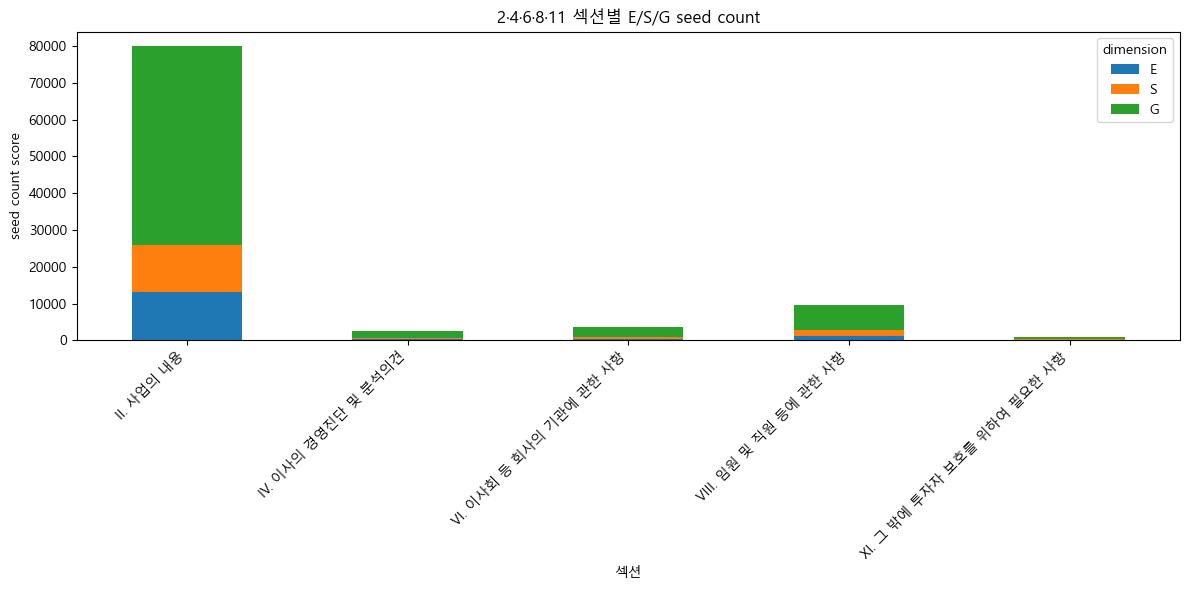

In [19]:
# ============================================================
# 19-1. 섹션별 E/S/G seed count 시각화
# ============================================================

section_esg_sum = (
    analysis_feature_df
    .groupby("section_clean", as_index=False)[
        [
            "seed_count_score_E",
            "seed_count_score_S",
            "seed_count_score_G"
        ]
    ]
    .sum()
)

section_order = [
    "II. 사업의 내용",
    "IV. 이사의 경영진단 및 분석의견",
    "VI. 이사회 등 회사의 기관에 관한 사항",
    "VIII. 임원 및 직원 등에 관한 사항",
    "XI. 그 밖에 투자자 보호를 위하여 필요한 사항"
]

section_esg_sum["section_clean"] = pd.Categorical(
    section_esg_sum["section_clean"],
    categories=section_order,
    ordered=True
)

section_esg_sum = section_esg_sum.sort_values("section_clean")

plot_df = section_esg_sum.set_index("section_clean")[
    [
        "seed_count_score_E",
        "seed_count_score_S",
        "seed_count_score_G"
    ]
]

plot_df.columns = ["E", "S", "G"]

plot_df.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6)
)

plt.xlabel("섹션")
plt.ylabel("seed count score")
plt.title("2·4·6·8·11 섹션별 E/S/G seed count")
plt.xticks(rotation=45, ha="right")
plt.legend(title="dimension")
plt.tight_layout()
plt.show()

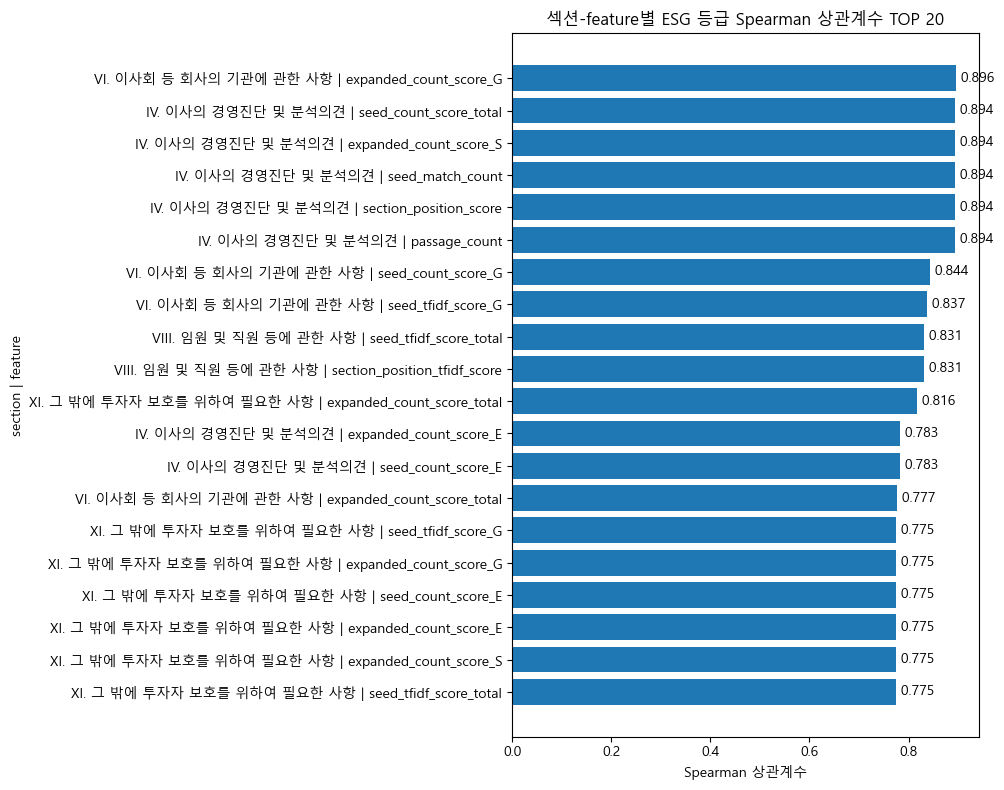

In [20]:
# ============================================================
# 19-2. feature별 Spearman 상관계수 TOP 20
# ============================================================

top_corr = (
    spearman_result_df
    .dropna(subset=["spearman_corr"])
    .sort_values("spearman_corr", ascending=False)
    .head(20)
    .copy()
)

top_corr["label"] = top_corr["section_clean"] + " | " + top_corr["feature"]

plt.figure(figsize=(10, 8))

plt.barh(
    top_corr["label"][::-1],
    top_corr["spearman_corr"][::-1]
)

plt.xlabel("Spearman 상관계수")
plt.ylabel("section | feature")
plt.title("섹션-feature별 ESG 등급 Spearman 상관계수 TOP 20")

for i, v in enumerate(top_corr["spearman_corr"][::-1]):
    plt.text(v, i, f" {v:.3f}", va="center")

plt.tight_layout()
plt.show()

# 20. 최종 데이터 저장

In [21]:
# ============================================================
# 20. 최종 데이터 저장
# ============================================================

feature_path = SECTION_DIR / "section_deep_feature_dataset.csv"
expanded_valid_path = SECTION_DIR / "expanded_terms_valid.csv"

analysis_feature_df.to_csv(
    feature_path,
    index=False,
    encoding="utf-8-sig"
)

valid_expanded_terms_df.to_csv(
    expanded_valid_path,
    index=False,
    encoding="utf-8-sig"
)

print("저장 완료:", feature_path)
print("저장 완료:", expanded_valid_path)
print("저장 완료:", spearman_path)
print("저장 완료:", group_test_path)
print("저장 완료:", sample_path)

저장 완료: c:\Users\duswl\OneDrive\바탕 화면\duswls3247\비정형 데이터 처리\Final\data\processed\analysis\section_deep_validation\section_deep_feature_dataset.csv
저장 완료: c:\Users\duswl\OneDrive\바탕 화면\duswls3247\비정형 데이터 처리\Final\data\processed\analysis\section_deep_validation\expanded_terms_valid.csv
저장 완료: c:\Users\duswl\OneDrive\바탕 화면\duswls3247\비정형 데이터 처리\Final\data\processed\analysis\section_deep_validation\section_feature_spearman_result.csv
저장 완료: c:\Users\duswl\OneDrive\바탕 화면\duswls3247\비정형 데이터 처리\Final\data\processed\analysis\section_deep_validation\section_feature_group_test_result.csv
저장 완료: c:\Users\duswl\OneDrive\바탕 화면\duswls3247\비정형 데이터 처리\Final\data\processed\analysis\section_deep_validation\manual_review_passage_samples.csv
